In [1]:
import logging

logging.basicConfig(level=logging.INFO, force=True)


from networkx.drawing import (
    draw as nx_draw,
    kamada_kawai_layout,
)
from networkx import get_node_attributes, connected_components
from networkx import nx_agraph
from mupt.graphs.generators import balanced_dendrimer_graph

from mupt.trees.subselect import NodePredicate
from mupt.mupr.primitives import (
    Primitive,
    RootPrimitive,
)
from mupt.mupr.properties import is_subdominant

from mupt.interfaces.smiles import primitive_from_smiles
from mupt.interfaces.mosdef.mbuild import primitive_to_mbuild

INFO:rdkit:Enabling RDKit 2026.09.1 jupyter extensions
INFO:freud.msd:Using SciPy's fftpack for FFTs


# PAMAM dendrimer

## Assemble MuPT repr

In [2]:
num_generations: int = 3
lexicon = {  # notice the values are Primitive instances; applied even if not all-atom
    "cyanogen": primitive_from_smiles(
        "[N:1](-[*:2])(-[*:2])CC[N:1](-[*:2])(-[*:2])", label="_C"
    ),
    "AAm": primitive_from_smiles(
        "[*:1]-[C:2]C(=O)NCC[N:1](-[*:2])(-[*:2])", label="_A"
    ),
    "AAm_T": primitive_from_smiles("[*:1]-[C:2]C(=O)NCC[NH2]", label="_B"),
}

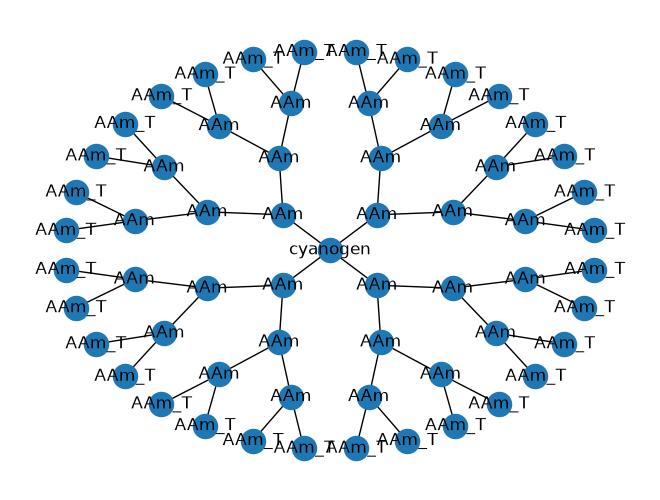

In [3]:
dendr = balanced_dendrimer_graph(
    coord_number=(lexicon["AAm"].functionality - 1),
    coord_number_core=lexicon["cyanogen"].functionality,
    num_generations=num_generations,
    core="cyanogen",
    shell_inner="AAm",
    shell_outer="AAm_T",
)

nx_draw(
    dendr,
    pos=nx_agraph.graphviz_layout(dendr, prog="twopi"),
    with_labels=True,
    labels=get_node_attributes(dendr, "label"),
)

### Select, connect, then inspect

In [4]:
# predicate : NodePredicate[Primitive] = lambda prim: isinstance(prim, CompositePrimitive)
# predicate : NodePredicate[Primitive] = lambda prim : is_atom(prim) and prim.element.symbol != 'H'
predicate: NodePredicate[Primitive] = is_subdominant

In [5]:
molprim = RootPrimitive()
molprim.populate_from_topology_and_lexicon(dendr, lexicon, label_attr="label")
xsec = molprim.cross_section(predicate)

print(f"{len(list(connected_components(xsec)))} molecules")

INFO:mupt.mupr.connection.linking:Paired up 60 new edges after 1 iteration(s); 0/60 edges remain unpaired
INFO:mupt.mupr.connection.linking:Linking protocol successful! 60/60 edges were assigned Connector pairings


1 molecules


In [6]:
# NOTE: this is the rate-limiting step here; not actually necessary for
# system setup, only for embedding nice-to-look-at positions.
# Will eventually be replaced w/ rigid/random walk initial coord gen
pos = kamada_kawai_layout(xsec, dim=2)

<Axes: >

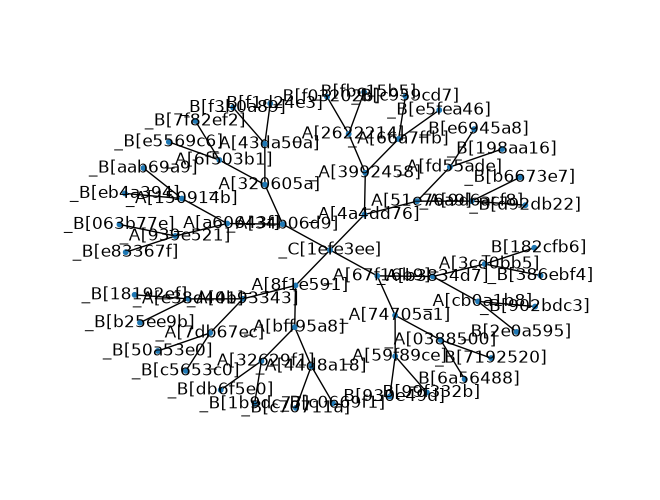

In [7]:
molprim.visualize_cross_section(
    xsec,
    pos=pos,
    with_labels=True,
    node_size=10,
)

## Export to mbuild

In [8]:
compound = primitive_to_mbuild(molprim, predicate=predicate)
...  # insert downstream code here
print(compound)

<ROOT 61 particles, 60 bonds, non-periodic, id: 5920450816>


In [9]:
import warnings

warnings.filterwarnings("ignore")
from flowermd.base import Molecule

molecules = Molecule(
    num_mols=1, compound=compound, name="PAMAM", identify_connections=False
)
molecules.compound.children[0].mass = 1

INFO:numexpr.utils:NumExpr defaulting to 11 threads.


In [10]:
molecules.molecules

[<PAMAM 61 particles, 60 bonds, non-periodic, id: 5997271696>]

In [11]:
molecules

In [12]:
from flowermd.library import RandomWalk
import unyt as u

ref_length = 1.0 * u.Unit("nm")
ref_mass = 1.0 * u.Unit("g/mol")
ref_energy = 1.0 * u.Unit("kcal / mol")
ref_values_dict = {"length": ref_length, "mass": ref_mass, "energy": ref_energy}

system = RandomWalk(
    molecules=molecules,
    density=0.8 * u.Unit("nm**-3"),
    bond_length=1.0,
    buffer=0.5,
    base_units=ref_values_dict,
    seed=456,
)
system.box

Box: Lx=4.240463, Ly=4.240463, Lz=4.240463, xy=0.000000, xz=0.000000, yz=0.000000, 

In [13]:
system.gmso_system.bond_types

<TopologyPotentialView(())>

In [14]:
from flowermd.library import Bead_Spring_DPD
import hoomd

nlist = hoomd.md.nlist.Cell(buffer=0.4, exclusions=["bond"])
system.apply_forcefield(
    force_field=Bead_Spring_DPD(), kT=1.0, r_cut=1.01, nlist=nlist
)

In [15]:
from flowermd.library import PhantomWalk
import hoomd

sim = PhantomWalk(
    initial_state=system.hoomd_snapshot,
    forcefield=system.hoomd_forcefield,
    gsd_write_freq=100,
    log_write_freq=50,
    n_steps_dpd=500,
    n_steps_fire=100,
    write_at_start=True,
)

for writer in sim.operations.writers:
    if isinstance(writer, hoomd.write.GSD):
        writer.flush()

Initializing simulation state from a gsd.hoomd.Frame.
Step 75 of 500; TPS: 739.85; ETA: 0.0 minutes
Step 150 of 500; TPS: 1453.6; ETA: 0.0 minutes
Step 225 of 500; TPS: 2147.4; ETA: 0.0 minutes
Step 300 of 500; TPS: 2822.33; ETA: 0.0 minutes
Step 375 of 500; TPS: 3483.06; ETA: 0.0 minutes
Step 450 of 500; TPS: 4130.37; ETA: 0.0 minutes
Step 25 of 100; TPS: 219298.25; ETA: 0.0 minutes
The closest particles after DPD + FIRE are:  1.002750039100647


INFO:gsd.fl:opening file: trajectory.gsd with mode: r
INFO:gsd.hoomd:opening HOOMDTrajectory: <gsd.fl.GSDFile object at 0x16558ab00>
INFO:gsd.hoomd:found 7 frames
INFO:gsd.fl:closing file: trajectory.gsd
INFO:gsd.fl:opening file: trajectory.gsd with mode: r
INFO:gsd.hoomd:opening HOOMDTrajectory: <gsd.fl.GSDFile object at 0x103008c40>
INFO:gsd.hoomd:found 7 frames
INFO:gsd.fl:closing file: trajectory.gsd


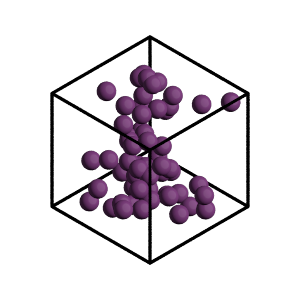

In [16]:
from cmeutils.visualize import FresnelGSD

sim_visualizer = FresnelGSD(
    gsd_file="trajectory.gsd", frame=0, view_axis=(1, 1, 1)
)
sim_visualizer.view()

INFO:gsd.fl:opening file: trajectory.gsd with mode: r
INFO:gsd.hoomd:opening HOOMDTrajectory: <gsd.fl.GSDFile object at 0x16559cf60>
INFO:gsd.hoomd:found 7 frames
INFO:gsd.fl:closing file: trajectory.gsd


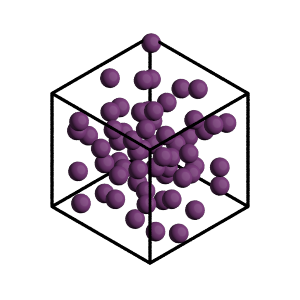

In [17]:
sim_visualizer.frame = -1
sim_visualizer.view()

In [20]:
snap = sim.state.get_snapshot()

In [21]:
snap.particles.position

array([[-0.35925381,  0.21491596, -1.95864892],
       [-0.46233382, -0.74161379,  2.00902535],
       [-0.79100021, -0.06417778,  1.3510366 ],
       [-1.44063571, -0.7772099 , -2.02732417],
       [-1.73356277, -0.38035846,  1.24314245],
       [-1.24156926,  0.66856812,  0.84114643],
       [-1.9679373 , -0.03246481, -1.61830526],
       [ 1.96628874, -1.02192065, -1.53200624],
       [-1.33615055, -1.29309687,  1.33788278],
       [ 1.6848905 , -0.44322237,  0.67710618],
       [-1.52060381,  0.55180375,  1.79431253],
       [-1.84583916,  1.46504284,  0.81992567],
       [ 1.35174639, -0.14919092, -1.24609101],
       [-1.98394875, -0.32845757, -0.66324611],
       [ 1.72527196, -1.38831382, -0.63330825],
       [-1.39624096, -1.27358578, -1.1247039 ],
       [ 0.50105913,  0.66197219,  2.03684047],
       [ 1.3604192 ,  1.17331163,  2.03882566],
       [ 0.26361424, -0.13232971,  1.47766878],
       [ 1.42372108,  1.97041288,  1.43835387],
       [ 1.65165637,  1.00569077, -1.259